# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'   # [정답안] 예시 번호
if not student_id or not student_id.isascii() or not student_id.isdigit():  # 비어 있거나, 영숫자 외 문자가 있거나, 숫자가 아니면 오류
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')  # 수험번호 형식 오류를 알리고 실행을 멈춤
print('수험번호:', student_id)  # 입력한 수험번호를 화면에 출력

수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 2-1. (예측)

> **[예측 문제]** 공식 샘플의 형식·제약을 그대로 따르고 데이터와 함정만 바꾼 연습 문제입니다. 실제 시험 문제가 아닙니다.

신상품 카테고리가 늘면서 **카테고리별 학습 사진 수가 크게 차이 나는(긴 꼬리, 최대 800장 ~ 최소 30장)** 데이터로 모델을 학습해야 합니다. 검증 데이터는 클래스마다 100장씩 균형입니다.

Task A, Task B, Task C로 이루어져 있으며, 수정해야 하는 셀에는 표시가 되어 있습니다. 그 외 셀은 수정하지 마세요.

- Task A는 `FashionModel`에서 학습 범위를 설정합니다. **고정: `patch_embed`, `stages[0]`, `stages[1]`, `stages[2]` / 학습: `stages[3]`, `head` 전체**
- Task B는 `custom_loss(logits, targets)`에 **클래스 불균형을 고려한 Loss**를 직접 구현합니다. (예: Focal Loss, 클래스 가중 CE, Logit Adjustment, Label Smoothing과의 조합)
- Task C는 `batch_size`, `learning_rate`, `epochs`를 조정합니다.
- 모델은 TinyViT 5M `dist_in22k_ft_in1k`, 입력 높이 80 × 너비 60 유지. 데이터 분할·전처리·구성 블록·가중치 로딩·학습/평가 코드는 수정 금지.

### 주의! 노트북에 반드시 포함
- 고정/학습 구간과 수정한 코드
- 선택한 Loss와 구현 코드, 선택 이유(주석)
- 비교한 하이퍼파라미터와 validation 결과, 최종 설정
- epoch별 validation macro-F1과 best validation macro-F1

> ## [예측 문제 정답안]
> Task A stages[3]+head 학습 / Task B 클래스 가중 Focal Loss / Task C 학습률·batch 조정

참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정

아래 셀은 가상환경이 설정되어 있으며 커널이 해당 가상환경으로 잡혀 있는지를 체크합니다.
꼭 실행해서 확인 후에 진행하세요. 오류가 발생하면 이 폴더의 README.md를 참고해 환경을 다시 확인하세요.
특히 VS Code, PyCharm 환경에서 Jupyter Notebook 커널을 꼭 확인하세요.


In [2]:
# [정답안] 환경 확인 - CPU/GPU 겸용 (문제 노트북은 GPU가 없으면 여기서 멈춥니다)
import sys  # 파이썬 인터프리터 정보(sys.prefix, sys.executable)를 쓰기 위한 모듈
from pathlib import Path  # 경로를 객체로 다루는 Path 클래스

print('Python:', sys.version.split()[0])  # 현재 파이썬 버전 출력 (예: 3.12.10)
print('현재 커널:', sys.executable)  # 지금 노트북을 실행 중인 python.exe 경로 출력 → .venv인지 확인
print('작업 폴더:', Path.cwd())  # 현재 작업 폴더 출력 (상대 경로 data/... 의 기준)
expected_env = Path.cwd() / '.venv'  # 작업 폴더 아래 .venv 폴더 경로를 기대값으로 만듦
if Path(sys.prefix).resolve() != expected_env.resolve():  # 실행 중인 파이썬의 환경 폴더가 기대한 .venv와 다르면
    raise RuntimeError(f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요.")  # 잘못된 커널 오류
import torch, torchvision, timm  # 세 라이브러리 한 번에 불러오기
print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)  # 설치된 세 라이브러리 버전 출력
if torch.cuda.is_available():  # CUDA GPU를 쓸 수 있으면
    DEVICE, QUICK = 'cuda', False  # 장치는 GPU, QUICK(축소 실행) 모드는 끔
    print('GPU:', torch.cuda.get_device_name(0), '-> 원본 설정 그대로 실행합니다.')  # GPU 이름 출력
else:  # 그렇지 않으면 (아래 실행)
    DEVICE, QUICK = 'cpu', True  # 장치는 CPU, QUICK 모드 켬 → 뒤의 [정답안 전용] 셀이 데이터·epoch를 줄임
    print('GPU 없음 -> QUICK 모드: 학습 데이터와 epoch를 줄여 CPU에서 끝까지 실행합니다 (점수는 낮게 나옴).')  # CPU 실행 안내

Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_final_predict


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
GPU: NVIDIA GeForce RTX 5060 Ti -> 원본 설정 그대로 실행합니다.


## 데이터 준비

환경과 데이터는 이미 준비되어 있습니다. VS Code 또는 PyCharm에서 이 폴더를 여세요. 노트북 커널/인터프리터는 이 폴더의 `.venv\Scripts\python.exe`를 선택합니다. 데이터는 같은 폴더의 `data/`에서 읽습니다. 이미지는 RGB, 가로 60 × 세로 80이며 리사이즈하지 않습니다. 이 노트북에서는 데이터를 다운로드하거나 다시 분할하지 않습니다. validation 데이터는 변경하지 마세요.
또한 DataLoader과 Transform 역시 수정하면 안 됩니다.

P1_1, P1_2, P2_1, P2_2는 노트북과 같은 폴더의 `tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors` 파일을 함께 사용합니다. 사전학습 가중치를 다운로드할 필요가 없습니다.


In [3]:
# 수정 금지

from pathlib import Path  # 경로를 객체로 다루는 Path 클래스
import random  # 파이썬 기본 난수 (시드 고정용)
import json  # JSON 파일(classes.json) 읽기용
import time  # 학습 시간 측정용

import numpy as np  # NumPy: 이미지 배열(N, H, W, 3) 처리
import matplotlib.pyplot as plt  # 그래프 그리기
import torch  # PyTorch: 텐서 연산·자동 미분·신경망
from torch import nn  # nn: 신경망 층(Linear, Conv2d 등)과 Loss 클래스
from torch.nn import functional as F  # F: 함수형 API (interpolate, log_softmax, pad 등)
from torch.utils.data import Dataset, DataLoader  # Dataset(데이터 한 개 꺼내기 규칙), DataLoader(배치로 묶기)
from torchvision import transforms as T  # 이미지 변환 모음을 T라는 이름으로 사용 (V1 API)
from sklearn.metrics import f1_score  # F1 점수 계산 함수

random.seed(42)  # 파이썬 random 시드 고정 → 실행마다 같은 결과
np.random.seed(42)  # NumPy 난수 시드 고정
torch.manual_seed(42)  # PyTorch 난수 시드 고정 (가중치 초기화, shuffle 순서)

device = 'cuda' if torch.cuda.is_available() else 'cpu'  # GPU가 있으면 'cuda', 없으면 'cpu'를 장치로 사용
print('사용 장치:', torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU')  # 사용 장치 이름 출력


사용 장치: NVIDIA GeForce RTX 5060 Ti


In [4]:
# 수정 금지

data_path = Path('data/f2_1_longtail/prepared.npz')  # F2_1 데이터 파일
if not data_path.is_file() or not data_path.with_name('classes.json').is_file():  # npz 파일이나 같은 폴더의 classes.json이 없으면
    raise FileNotFoundError('데이터가 없습니다. 먼저 setup.cmd를 실행하고, 작업 폴더를 이 노트북이 있는 폴더로 맞추세요.')  # 데이터 준비가 안 됐다는 오류

In [5]:
# 수정 금지

with data_path.with_name('classes.json').open(encoding='utf-8') as file:  # classes.json을 UTF-8로 열기 (with: 끝나면 자동으로 닫힘)
    class_names = json.load(file)  # 클래스 이름 목록 읽기 (목록 순서 = 클래스 번호)
num_classes = len(class_names)  # 클래스 개수

with np.load(data_path, allow_pickle=False) as data:  # npz 열기 (allow_pickle=False: 안전하게 배열만 읽음)
    train_images = data['train_images']  # 학습 이미지 배열 (N, 80, 60, 3) uint8
    train_labels = data['train_labels'].reshape(-1)  # (N,1)이어도 (N,)으로 펼침
    val_images = data['val_images']  # 검증 이미지 배열
    val_labels = data['val_labels'].reshape(-1)  # (N,)으로 펼침

print('클래스:', num_classes)  # 클래스 수 출력
print('학습:', len(train_images), '검증:', len(val_images))  # 개수 출력
print('이미지 크기:', train_images[0].shape)  # 이미지 크기 출력


클래스: 20
학습: 4844 검증: 2000
이미지 크기: (80, 60, 3)


> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [6]:
# [정답안 전용] CPU QUICK 모드에서만 데이터를 줄입니다.
if QUICK:  # CPU(QUICK) 모드일 때만
    _rng = np.random.default_rng(0)  # QUICK용 난수 생성기
    _keep = np.sort(_rng.choice(len(train_labels), size=min(3000, len(train_labels)), replace=False))  # 학습 데이터에서 3,000개 번호를 중복 없이 뽑아 정렬
    train_images, train_labels = train_images[_keep], train_labels[_keep]  # 뽑은 것만 남김
    _keep = np.sort(_rng.choice(len(val_labels), size=min(800, len(val_labels)), replace=False))  # QUICK: 검증 800개
    val_images, val_labels = val_images[_keep], val_labels[_keep]  # 뽑은 검증만 남김
    print('QUICK 모드 데이터:', len(train_labels), len(val_labels))  # 줄인 개수 출력

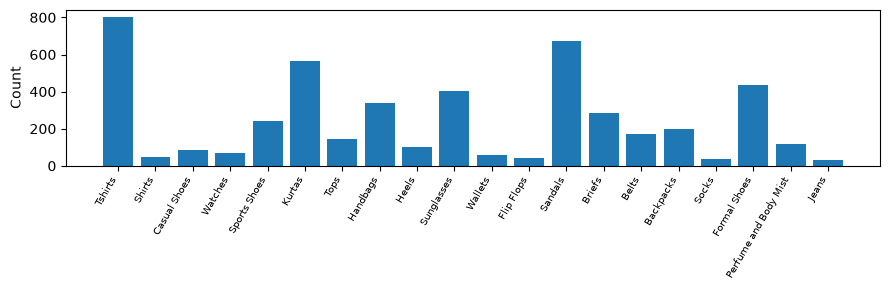

In [7]:
# 수정 금지
# Task B에서 사용할 수 있는 클래스별 학습 이미지 수입니다.

class_counts = torch.bincount(torch.as_tensor(train_labels), minlength=num_classes).float()  # 클래스별 학습 이미지 수 (Loss에서 사용 가능)
plt.figure(figsize=(9, 3))  # 그림
plt.bar(range(num_classes), class_counts.numpy())  # 개수 막대그래프
plt.xticks(range(num_classes), class_names, rotation=60, ha='right', fontsize=7)  # 클래스 이름 60도 기울임
plt.ylabel('Count')  # y축 이름
plt.tight_layout()  # 여백 자동 정리
plt.show()  # 그림 표시

In [8]:
# 수정 금지

mean = (0.485, 0.456, 0.406)  # ImageNet 채널별 평균 (사전학습 때 쓴 값)
std = (0.229, 0.224, 0.225)  # ImageNet 채널별 표준편차
eval_transform = T.Compose([  # 평가용 변환: 증강 없이 텐서 변환 + 정규화만
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
])


In [9]:
# 수정 금지

class FashionDataset(Dataset):  # 이미지·라벨·증강 여부로 샘플을 꺼내는 Dataset
    def __init__(self, images, labels, transform):  # 이미지·라벨·변환을 받는 생성자
        self.images = images  # 이미지 배열 저장
        self.labels = labels  # 라벨 배열 저장
        self.transform = transform  # 적용할 변환 저장

    def __len__(self):  # 데이터 개수를 알려주는 함수 (DataLoader가 사용)
        return len(self.images)  # 데이터 개수

    def __getitem__(self, index):  # index번째 샘플을 꺼내는 함수
        return self.transform(self.images[index]), int(self.labels[index])  # 변환한 이미지와 정수 라벨 반환


## Task A. 학습 가능 레이어 구간 설정

### 문제 목표
제공된 `FashionModel`은 마지막 분류기만 학습하는 Linear Probing 코드입니다.

모델 전체를 학습하는 대신, 앞쪽 구간은 고정하고 뒤쪽 구간만 학습하도록 수정하세요.

- 고정할 구간: `patch_embed`, `stages[0]`, `stages[1]`, `stages[2]`
- 학습할 구간: `stages[3]`, `head` 전체(`norm`, `fc`)

학습할 파라미터의 gradient 설정과 각 구간의 학습·평가 모드도 함께 확인하세요.

고정한 구간은 학습 중에도 가중치와 BatchNorm의 통계가 바뀌지 않아야 하며, 학습할 구간은 역전파로 가중치가 갱신되어야 합니다.

검증에서는 모델 전체가 평가 모드로 동작해야 합니다.

아래 구성 블록은 제공 코드입니다. 마지막 **`FashionModel` 셀만 수정**하세요.
클래스의 구성과 파라미터 크기, `load_pretrained_weights()` 호출은 유지하고, `__init__()`과 `forward()`에서 학습 범위를 설정하세요.

### 공식 문서

- [`torch.no_grad`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.no_grad--0a86b42ac45c.html): gradient 계산을 기록하지 않는 구간
- [`Module.requires_grad_`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.Module--4a31c4b64903.html#torch.nn.Module.requires_grad_): 파라미터의 gradient 계산 여부
- [`Module.train`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.Module--4a31c4b64903.html#torch.nn.Module.train) · [`Module.eval`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.Module--4a31c4b64903.html#torch.nn.Module.eval): 학습 모드와 평가 모드
- [Autograd의 gradient 제어](docs/pages/docs.pytorch.org/docs_2.11_notes_autograd--222eba10ccf6.html#locally-disabling-gradient-computation): `no_grad`, 파라미터 고정, 평가 모드의 차이
- TinyViT 구조
  - 참고: [TinyViT 논문](docs/pages/arxiv.org/abs_2207.10666--75d1c6c4be04.html),
  - [Microsoft 공식 구현](docs/pages/github.com/microsoft_Cream_blob_main_TinyViT_models_tiny_vit.py--7c367b0b0023.html),
  - [사용한 사전학습 모델](docs/pages/huggingface.co/timm_tiny_vit_5m_224.dist_in22k_ft_in1k--7b8991aa746a.html)
  - 문제 2-2의 그림 참고
  - 이 과제에서는 입력을 80×60으로, attention window 크기를 3·5·3으로 조정했습니다.

### Patch Embedding

입력 `(B, 3, 80, 60)`을 특징 맵 `(B, 64, 20, 15)`로 바꿉니다.


In [10]:
# 수정 금지

class ConvNorm(nn.Sequential):  # Conv2d + BatchNorm2d 묶음 (nn.Sequential을 상속)
    """Conv2d와 BatchNorm2d로 구성한 기본 블록."""  # 클래스 설명(docstring)
    def __init__(self, in_channels, out_channels, kernel_size=1,  # 입력 채널, 출력 채널, 커널 크기
                 stride=1, padding=0, groups=1, bn_weight=1.0):  # stride, padding, 그룹 수(depthwise면 채널 수), BN 초기 가중치
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv = nn.Conv2d(  # 합성곱 층
            in_channels, out_channels, kernel_size,  # 채널·커널
            stride=stride, padding=padding, groups=groups, bias=False,  # bias는 BN이 대신하므로 False
        )
        self.bn = nn.BatchNorm2d(out_channels)  # 배치 정규화 층
        nn.init.constant_(self.bn.weight, bn_weight)  # BN 스케일 초기값
        nn.init.zeros_(self.bn.bias)  # BN 이동값 0으로 초기화


class PatchEmbed(nn.Module):  # 입력 이미지를 특징 맵으로 바꾸는 첫 블록
    """원본 입력을 특징 맵으로 변환: [B, 3, 80, 60] → [B, 64, 20, 15]."""  # 클래스 설명(docstring)
    def __init__(self, dim=64):  # dim=64: 출력 채널 수
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv1 = ConvNorm(3, dim // 2, 3, stride=2, padding=1)  # 3→32채널, stride 2 (해상도 1/2)
        self.act = nn.GELU()  # GELU 활성화
        self.conv2 = ConvNorm(dim // 2, dim, 3, stride=2, padding=1)  # 32→64채널, stride 2 (해상도 1/4)

    def forward(self, x):  # 순전파 정의
        x = self.conv1(x)  # 첫 합성곱
        x = self.act(x)  # 활성화
        return self.conv2(x)  # 두 번째 합성곱 결과 반환

### 합성곱 블록

첫 stage의 MBConv와 해상도를 줄이는 Patch Merging입니다.


In [11]:
# 수정 금지

class MBConv(nn.Module):  # MobileNet식 역병목 합성곱 블록 (stage 0)
    """Stage 0: 채널 확장 → depthwise convolution → 채널 축소."""  # 클래스 설명(docstring)
    def __init__(self, dim, expand_ratio=4):  # expand_ratio=4: 중간 채널을 4배로 늘림
        super().__init__()  # nn.Module 초기화 (필수)
        hidden_dim = dim * expand_ratio  # 중간 채널 수
        self.conv1 = ConvNorm(dim, hidden_dim)  # 1×1 합성곱으로 채널 확장
        self.act1 = nn.GELU()  # 활성화
        self.conv2 = ConvNorm(hidden_dim, hidden_dim, 3,  # 3×3 depthwise 합성곱 (채널별로 따로)
                              padding=1, groups=hidden_dim)  # padding 1, groups=채널 수
        self.act2 = nn.GELU()  # 활성화
        self.conv3 = ConvNorm(hidden_dim, dim, bn_weight=0.0)  # 1×1로 채널 축소 (BN 가중치 0 → 처음엔 항등 연결처럼 동작)
        self.act3 = nn.GELU()  # 활성화

    def forward(self, x):  # 순전파 정의
        shortcut = x  # 잔차 연결용 입력 저장
        x = self.act1(self.conv1(x))  # 확장 + 활성화
        x = self.act2(self.conv2(x))  # depthwise + 활성화
        x = self.conv3(x)  # 축소
        return self.act3(x + shortcut)  # 입력을 더한 뒤(잔차) 활성화


class ConvStage(nn.Module):  # MBConv 여러 개를 쌓은 stage
    def __init__(self, dim, depth):  # 채널, 블록 개수
        super().__init__()  # nn.Module 초기화 (필수)
        self.blocks = nn.Sequential(*[MBConv(dim) for _ in range(depth)])  # depth개의 MBConv를 순서대로 연결

    def forward(self, x):  # 순전파 정의
        return self.blocks(x)  # 블록들 통과


class PatchMerging(nn.Module):  # 해상도를 절반으로 줄이며 채널을 바꾸는 블록
    """해상도를 절반으로 줄이고 다음 stage의 채널 수로 변환."""  # 클래스 설명(docstring)
    def __init__(self, in_dim, out_dim):  # 입력·출력 채널
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv1 = ConvNorm(in_dim, out_dim)  # 1×1로 채널 변경
        self.act1 = nn.GELU()  # 활성화
        self.conv2 = ConvNorm(out_dim, out_dim, 3, stride=2,  # 3×3 depthwise, stride 2 (해상도 1/2)
                              padding=1, groups=out_dim)  # padding 1, groups=채널 수
        self.act2 = nn.GELU()  # 활성화
        self.conv3 = ConvNorm(out_dim, out_dim)  # 1×1 합성곱

    def forward(self, x):  # 순전파 정의
        x = self.act1(self.conv1(x))  # 확장 + 활성화
        x = self.act2(self.conv2(x))  # depthwise + 활성화
        return self.conv3(x)  # 마지막 합성곱 결과 반환

### Window Attention과 MLP

각 window 안의 위치 관계를 상대 위치 bias로 표현합니다.


In [12]:
# 수정 금지

class NormMLP(nn.Module):  # LayerNorm → Linear → GELU → Linear 다층 퍼셉트론
    def __init__(self, dim, mlp_ratio=4):  # mlp_ratio=4: 중간 차원 4배
        super().__init__()  # nn.Module 초기화 (필수)
        self.norm = nn.LayerNorm(dim)  # 토큰별 LayerNorm
        self.fc1 = nn.Linear(dim, dim * mlp_ratio)  # 차원 확장
        self.act = nn.GELU()  # GELU 활성화
        self.fc2 = nn.Linear(dim * mlp_ratio, dim)  # 차원 복원

    def forward(self, x):  # 순전파 정의
        x = self.norm(x)  # 정규화
        x = self.fc1(x)  # 확장
        x = self.act(x)  # 활성화
        return self.fc2(x)  # 복원 결과 반환


class WindowAttention(nn.Module):  # window 안에서만 하는 multi-head self-attention
    """작은 window 안에서 수행하는 multi-head self-attention."""  # 클래스 설명(docstring)
    def __init__(self, dim, num_heads, window_size):  # 차원, head 수, window 한 변 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.num_heads = num_heads  # head 수 저장
        self.head_dim = dim // num_heads  # head 하나의 차원
        self.scale = self.head_dim ** -0.5  # 점수 스케일 1/√(head 차원)
        self.norm = nn.LayerNorm(dim)  # 토큰별 LayerNorm
        self.qkv = nn.Linear(dim, dim * 3)  # Q, K, V를 한 번에 만드는 Linear (출력 3배)
        self.proj = nn.Linear(dim, dim)  # head를 합친 뒤 출력 투영

        # window 내 두 위치 사이의 상대 거리에 따른 학습 가능한 bias
        coords = torch.stack(torch.meshgrid(  # window 안 모든 위치의 (행, 열) 좌표
            torch.arange(window_size), torch.arange(window_size), indexing="ij"  # 0..window-1 격자
        )).flatten(1)  # (2, window²) 모양으로 펼침
        offsets = (coords[:, :, None] - coords[:, None, :]).abs()  # 모든 위치 쌍의 행·열 거리 (절댓값)
        bias_indices = offsets[0] * window_size + offsets[1]  # 거리 (dy, dx)를 bias 표의 번호로 바꿈
        self.register_buffer("attention_bias_idxs", bias_indices, persistent=False)  # 번호표를 버퍼로 저장 (학습 안 함, state_dict에도 안 넣음)
        self.attention_biases = nn.Parameter(  # 거리별 학습 가능한 bias 표
            torch.zeros(num_heads, window_size * window_size)  # (head 수, window²) 크기, 0으로 시작
        )

    def forward(self, x):  # 순전파 정의
        batch_size, num_tokens, dim = x.shape  # (window 개수×배치, 토큰 수, 차원)
        x = self.norm(x)  # 정규화

        # 체크포인트의 QKV 배치 순서: 각 head 안에 Q, K, V가 들어 있습니다.
        qkv = self.qkv(x).reshape(  # QKV 계산 후 모양 변경
            batch_size, num_tokens, self.num_heads, 3 * self.head_dim  # (B, N, head, 3×head 차원): head마다 [q|k|v]가 붙어 있음
        )
        qkv = qkv.transpose(1, 2)  # (B, head, N, 3×head 차원)
        q, k, v = qkv.chunk(3, dim=-1)  # 마지막 축을 3등분 → q, k, v

        attention = (q * self.scale) @ k.transpose(-2, -1)  # 스케일된 Q·Kᵀ = 위치 쌍별 유사도 (B, head, N, N)
        bias = self.attention_biases[:, self.attention_bias_idxs]  # 각 위치 쌍의 거리에 해당하는 bias를 꺼냄
        attention = (attention + bias.unsqueeze(0)).softmax(dim=-1)  # bias를 더하고 softmax → 주의 가중치
        x = attention @ v  # 가중치로 V를 섞음
        x = x.transpose(1, 2).reshape(batch_size, num_tokens, dim)  # head들을 다시 이어붙여 (B, N, 차원)
        return self.proj(x)  # 출력 투영 결과 반환

### Attention 블록과 Stage

특징 맵을 window로 나누고, 추가한 여백은 attention 후 제거합니다.


In [13]:
# 수정 금지

class TinyViTBlock(nn.Module):  # attention + local conv + MLP 블록
    """Window attention → local convolution → MLP."""  # 클래스 설명(docstring)
    def __init__(self, dim, num_heads, window_size):  # 차원, head 수, window 한 변 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.window_size = window_size  # window 크기 저장
        self.attn = WindowAttention(dim, num_heads, window_size)  # window attention 층
        self.local_conv = ConvNorm(dim, dim, 3, padding=1, groups=dim)  # 3×3 depthwise 합성곱 (가까운 위치 정보 섞기)
        self.mlp = NormMLP(dim)  # MLP 층

    def forward(self, x):  # 순전파 정의
        # 이 블록 안에서는 [B, H, W, C] 순서로 처리합니다.
        batch_size, height, width, channels = x.shape  # (B, H, W, C) 모양 분해
        shortcut = x  # 잔차 연결용 입력 저장
        window = self.window_size  # window 크기

        # 해상도가 window 크기의 배수가 아닐 때 오른쪽·아래쪽에 padding
        pad_h = (window - height % window) % window  # 높이를 window 배수로 맞출 아래쪽 padding
        pad_w = (window - width % window) % window  # 너비를 window 배수로 맞출 오른쪽 padding
        x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))  # (채널, 너비, 높이) 순서로 0 padding
        padded_h, padded_w = height + pad_h, width + pad_w  # padding 후 크기
        num_h, num_w = padded_h // window, padded_w // window  # 세로·가로 window 개수

        # 이미지 → 여러 window
        x = x.reshape(batch_size, num_h, window, num_w, window, channels)  # window 단위로 나눔
        x = x.transpose(2, 3).reshape(-1, window * window, channels)  # (B×window 개수, window², C) 토큰 묶음으로
        x = self.attn(x)  # window마다 attention

        # 여러 window → 이미지
        x = x.reshape(batch_size, num_h, num_w, window, window, channels)  # 다시 window 격자 모양으로
        x = x.transpose(2, 3).reshape(batch_size, padded_h, padded_w, channels)  # 이미지 모양 (B, H', W', C)로 복원
        x = x[:, :height, :width, :].contiguous()  # padding 부분 잘라냄
        x = shortcut + x  # 잔차 연결

        x = x.permute(0, 3, 1, 2)  # (B, C, H, W)로 바꿈 (합성곱 입력 형식)
        x = self.local_conv(x)  # local 합성곱
        x = x.flatten(2).transpose(1, 2)  # (B, H×W, C) 토큰 형식으로
        x = x + self.mlp(x)  # MLP + 잔차 연결
        return x.reshape(batch_size, height, width, channels)  # (B, H, W, C)로 되돌려 반환


class TinyViTStage(nn.Module):  # PatchMerging + TinyViTBlock 여러 개
    def __init__(self, in_dim, out_dim, depth, num_heads, window_size):  # 입력·출력 채널, 블록 수, head 수, window 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.downsample = PatchMerging(in_dim, out_dim)  # 해상도 절반 + 채널 변경
        self.blocks = nn.Sequential(*[  # 블록들을 순서대로 연결
            TinyViTBlock(out_dim, num_heads, window_size) for _ in range(depth)  # depth개의 attention 블록
        ])

    def forward(self, x):  # 순전파 정의
        x = self.downsample(x)  # 해상도 줄이기 (B, C, H, W)
        x = x.permute(0, 2, 3, 1)  # (B, H, W, C)로 바꿈 (블록 입력 형식)
        x = self.blocks(x)  # 블록들 통과
        return x.permute(0, 3, 1, 2)  # (B, C, H, W)로 되돌려 반환

### 사전학습 가중치

1,000종 분류 가중치를 `strict=True`로 불러온 뒤 분류기를 20종으로 교체합니다. 상대 위치 bias만 작은 window에 맞춰 보간합니다. 이 셀은 수정하지 마세요.


In [14]:
# 수정 금지
# 사전학습 가중치 로딩과 출력 분류기입니다.

from safetensors.torch import load_file  # safetensors 형식 가중치 파일을 읽는 함수


class ClassifierHead(nn.Module):  # 평균 풀링 → LayerNorm → Linear 분류 head
    def __init__(self, dim, num_classes):  # 입력 차원, 클래스 수
        super().__init__()  # nn.Module 초기화 (필수)
        self.norm = nn.LayerNorm(dim, eps=1e-5)  # 정규화 층
        self.fc = nn.Linear(dim, num_classes)  # 분류층

    def forward(self, x):  # 순전파 정의
        x = x.mean(dim=(2, 3))  # 공간(H, W) 평균 → (B, C) 특징 벡터
        x = self.norm(x)  # 정규화
        return self.fc(x)  # 클래스 점수 반환


def load_pretrained_weights(model):  # 로컬 사전학습 가중치를 모델에 넣는 함수
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""  # 함수 설명(docstring)
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')  # 노트북 옆에 있어야 할 가중치 파일
    if not path.is_file():  # 파일이 없으면
        raise FileNotFoundError(  # 오류 발생
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'  # 찾은 절대 경로를 오류 문구에 넣음
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'  # 오류 안내 두 번째 줄
        )
    weights = load_file(str(path))  # 가중치를 {이름: 텐서} 사전으로 읽음
    target = model.state_dict()  # 현재 모델의 {이름: 텐서} (모양 비교용)
    for name, value in weights.items():  # 가중치를 하나씩 돌며
        if name.endswith('attention_biases') and value.shape != target[name].shape:  # attention 상대 위치 bias인데 모양이 다르면 (window 크기를 줄였기 때문)
            num_heads, length = value.shape  # (head 수, window²) 모양 분해
            old_window = int(length ** 0.5)  # 원래 window 한 변 길이 (예: 49 → 7)
            new_window = int(target[name].shape[1] ** 0.5)  # 새 window 한 변 길이 (예: 9 → 3)
            weights[name] = F.interpolate(  # bias를 2차원 격자로 보고 크기를 줄임
                value.float().reshape(1, num_heads, old_window, old_window),  # (1, head, 원래 window, 원래 window) 이미지처럼 바꿈
                size=(new_window, new_window),  # 목표 크기
                mode='bicubic', antialias=True,  # bicubic 보간 + antialias (부드럽게 축소)
            ).reshape(num_heads, new_window * new_window)  # 다시 (head, 새 window²) 모양으로
    model.load_state_dict(weights, strict=True)  # strict=True: 모든 이름·모양이 정확히 맞아야 로딩 (빠진 것 있으면 오류)


# **답안 작성 셀 - 학습 레이어 구간 정의**

### 주의!
* 매 실험은 제공된 사전학습 가중치로부터 모델 학습이 진행되어야 합니다.


In [15]:
# 수정 가능
class FashionModel(nn.Module):  # 20종 분류용 TinyViT 5M
    """[정답안] 고정: patch_embed, stages[0..2] / 학습: stages[3], head"""  # 클래스 설명(docstring)
    def __init__(self):  # 생성자
        super().__init__()  # nn.Module 초기화 (필수)
        self.patch_embed = PatchEmbed(dim=64)  # 입력 → 64채널 특징 맵
        self.stages = nn.Sequential(  # 4개 stage 묶음
            ConvStage(dim=64, depth=2),  # stage 0: MBConv 2개 (64채널)
            TinyViTStage(64, 128, depth=2, num_heads=4, window_size=3),  # stage 1: 128채널, 블록 2, head 4, window 3
            TinyViTStage(128, 160, depth=6, num_heads=5, window_size=5),  # stage 2: 160채널, 블록 6, head 5, window 5
            TinyViTStage(160, 320, depth=2, num_heads=10, window_size=3),  # stage 3: 320채널, 블록 2, head 10, window 3
        )
        self.head = ClassifierHead(320, num_classes=1000)  # 원래 1000종 head (가중치 로딩을 위해 같은 모양으로 만듦)
        load_pretrained_weights(self)  # 사전학습 가중치 로딩 (strict)
        self.head.fc = nn.Linear(320, num_classes)  # 분류층을 20종 출력으로 교체

        self.requires_grad_(False)  # 일단 전체 파라미터 고정
        self.stages[3].requires_grad_(True)  # stage 3를 학습 가능하게
        self.head.requires_grad_(True)  # head 전체(norm + fc) 학습

    def train(self, mode=True):  # model.train()/eval()이 부르는 함수를 덮어씀
        super().train(mode)  # 원래 동작: 전체를 mode로 설정
        for module in (self.patch_embed, self.stages[0], self.stages[1], self.stages[2]):  # 고정 구간 4개
            module.train(False)          # 고정 구간 BatchNorm 통계 유지
        return self  # nn.Module 관례대로 자기 자신 반환

    def forward(self, x):  # 순전파 정의
        with torch.no_grad():  # gradient 기록 없이 계산 (메모리·속도 절약)
            x = self.patch_embed(x)  # 특징 맵 만들기
            x = self.stages[0](x)  # stage 0
            x = self.stages[1](x)  # stage 1
            x = self.stages[2](x)  # stage 2
        x = self.stages[3](x)  # stage 3
        x = x.mean(dim=(2, 3))  # 공간(H, W) 평균 → (B, C) 특징 벡터
        x = self.head.norm(x)  # LayerNorm
        return self.head.fc(x)  # 최종 출력

## Task B. Loss 구현 

### 문제 목표

`custom_loss(logits, targets)` 함수를 작성하세요.
**클래스 불균형을 고려한** 분류 Loss를 PyTorch 텐서 연산으로 직접 구현해야 합니다. 위 셀의 `class_counts`(클래스별 학습 이미지 수, `(클래스 수,)` 실수 텐서)를 사용해도 됩니다.

- `logits`는 모델이 출력한 클래스별 점수이며, softmax가 적용되지 않은 `(배치 크기, 클래스 수)` 텐서입니다.
- `targets`는 각 이미지의 정답 클래스 번호가 들어 있는 `(배치 크기,)` 정수 텐서입니다.
- 배치 평균 Loss를 유한한 스칼라 텐서(실수 값)로 반환하세요. 반환값은 `logits`와 같은 장치(device=cpu 또는 gpu)에 있고, `logits`에 대해 역전파가 가능해야 합니다.

클래스 번호와 정답의 대응, 함수 이름과 입력 인자는 변경하지 마세요.

### 사용 가능한 연산

Loss의 **구성 요소를 계산하는 기본 연산**은 사용할 수 있습니다. 아래는 허용되는 연산의 예시입니다.

- 사칙연산(`+`, `-`, `*`, `/`), 거듭제곱 (`**` 또는 `pow`), 비교 연산과 마스크
- `sum`, `mean`, `log`, `exp`, `logsumexp`, `abs`, `square`, `clamp`, `maximum`
- `softmax`, `log_softmax`, `sigmoid`, `relu`
- 인덱싱, 슬라이싱, `gather`, `reshape`, `unsqueeze`, 브로드캐스팅
- `one_hot`, `arange`, `zeros_like`, `ones_like`, 자료형·장치 변환

`F`는 `torch.nn.functional`입니다. `F.log_softmax`와 `F.one_hot`도 허용합니다.\
각각 로그 확률과 정답 표현을 만드는 연산이며, 완성된 Loss를 계산하지 않는 단위 연산이기 때문입니다. 위 연산을 조합한 보조 함수를 직접 작성해도 됩니다.

### 사용하면 안 되는 API

Loss 계산을 대신하는 **완성형 Loss API**는 객체와 함수 모두 금지합니다. 예를 들면 다음과 같습니다.

- `nn.CrossEntropyLoss`, `nn.NLLLoss`, `nn.MSELoss`, `nn.MultiMarginLoss` 등
- `F.cross_entropy`, `F.nll_loss`, `F.mse_loss`, `F.kl_div`, `F.binary_cross_entropy`, `F.binary_cross_entropy_with_logits`, `F.multi_margin_loss` 등
- `torchvision.ops.sigmoid_focal_loss` 같은 외부 라이브러리의 완성형 Loss

이름을 바꾸거나 다른 함수로 감싸서 호출하는 것도 금지합니다. `torch.distributions`의 `log_prob()`로 손실 계산을 대신하지 마세요. \
기준은 `nn`이나 `F` 소속인지가 아니라, **Loss 수식을 직접 계산했는지**입니다.

반환할 Loss를 계산하는 과정에서 `detach()`, `item()`, NumPy 변환, `torch.tensor(계산한_loss)` 등으로 계산 그래프를 끊지 마세요.\
 이 조건은 `custom_loss()`의 계산에 대한 것으로, 제공된 학습 코드의 기록용 `loss.item()`이나 Task A의 구간 고정에는 적용되지 않습니다.

### 공식 문서

직접 구현할 때 사용할 수 있는 기본 연산입니다. 각 문서에서 인자와 입력·출력 형태를 확인하세요.

- [`F.one_hot`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.functional.one_hot--9dd35c62b72b.html): 정수 클래스 번호를 one-hot 텐서로 변환
- [`torch.gather`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.gather--7bcfaf478b08.html): 지정한 축에서 인덱스에 해당하는 값 선택
- [`F.log_softmax`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.functional.log_softmax--b0a42ff641a4.html): 지정한 축을 따라 로그 확률 계산
- [`torch.log`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.log--cb2985075d35.html) · [`torch.exp`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.exp--4ba900f07364.html): 원소별 자연로그·지수 계산
- [`torch.sum`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.sum--09b7ca212d74.html) · [`torch.mean`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.mean--d857c1f57e9d.html): 전체 또는 지정한 축의 합·평균 계산
- [`torch.clamp`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.clamp--fa889aae90bc.html): 값을 지정한 최솟값·최댓값 범위로 제한

텐서 연산과 자동 미분의 관계는 [PyTorch Autograd mechanics](docs/pages/docs.pytorch.org/docs_2.11_notes_autograd--222eba10ccf6.html)를 참고하세요.

In [16]:
# 수정 가능

def custom_loss(logits, targets):  # 직접 구현하는 Loss 함수 (이름·인자 고정)
    """[정답안] 클래스 가중 Focal Loss (gamma=2, 가중치 = (1/n_c)^0.5 정규화)

    선택 이유 (주석)
      - 긴 꼬리 데이터에서 보통 CE는 다수 클래스(800장) 쪽으로 결정 경계가 밀려 소수 클래스(30장) F1이 낮습니다.
      - 클래스 가중치: 적은 클래스의 오류에 더 큰 벌점. 1/n 그대로 쓰면 30장 클래스가 너무 커서 불안정하므로
        제곱근으로 완화하고 평균 1이 되도록 정규화합니다.
      - Focal 항 (1-p_t)^gamma: 이미 잘 맞히는 쉬운 샘플(대부분 다수 클래스)의 Loss를 줄여
        어려운 샘플에 학습을 집중합니다.
    수식: loss_i = -w[y_i] * (1 - p_i[y_i])^gamma * log p_i[y_i],  배치 가중 평균
    """
    gamma = 2.0  # focal 지수: 클수록 쉬운 샘플 Loss를 더 줄임
    weights = class_counts.to(logits.device).clamp(min=1).pow(-0.5)  # 클래스 가중치 = 1/√개수 (적은 클래스일수록 큼)
    weights = weights / weights.mean()  # 평균이 1이 되도록 정규화
    log_probs = F.log_softmax(logits.float(), dim=1)  # log 확률 (float로 바꿔 수치 안정)
    log_pt = log_probs.gather(1, targets.long().unsqueeze(1)).squeeze(1)  # 정답 클래스의 log p
    pt = log_pt.exp()  # 정답 확률 p
    w = weights[targets]  # 샘플별 가중치
    loss = -w * (1.0 - pt).pow(gamma) * log_pt  # 가중 focal: -w (1-p)^γ log p
    return loss.sum() / w.sum()  # 가중 평균 (스칼라)

## Task C. Hyperparameter Tuning

### 문제 목표
Task A에서 정한 학습 구간과 Task B에서 구현한 Loss를 사용하고, 하이퍼파라미터를 조정해 validation macro-F1을 높이세요.
아래 셀의 `batch_size`, `learning_rate`, `epochs`만 변경할 수 있습니다.

- 초기 설정은 batch 크기 64, 학습률 0.0003, 20 epoch입니다.
- 설정을 바꿀 때마다 아래 DataLoader와 학습 셀을 다시 실행하세요. 모델은 같은 사전학습 가중치에서 시작합니다.
- 비교한 설정과 validation 결과를 노트북에 기록(저장, `ctrl+s`)하고 최종 설정을 선택하세요.
- validation은 평가에만 사용합니다. 학습 데이터에 추가하지 마세요.
- 저장 경로와 파일명은 변경하지 마세요. 수험번호가 자동으로 들어갑니다.

### 공식 문서

- [PyTorch 학습 루프와 하이퍼파라미터](docs/pages/docs.pytorch.org/tutorials_beginner_basics_optimization_tutorial--ad1a8b720acf.html)
- [`torch.optim.Adam`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.optim.Adam--97cb307dea19.html)


# **답안 작성 셀**

In [17]:
# 수정 가능

# [정답안] 비교 (Task A + 가중 Focal, 시드 42) -> README의 실행 결과 표 참고
batch_size = 32  # batch 크기 32
learning_rate = 0.0003  # 학습률
epochs = 20  # epoch 수 20

### [정답안 해설]
- 학습 범위가 `stages[3]`+`head`로 좁으므로 학습률은 샘플(2-1)보다 높게(3e-4) 써도 안정적입니다.
- 불균형 대응은 **Loss에서만** 해야 합니다(데이터·샘플러 수정 금지). 가중 CE, Focal, Logit Adjustment(`logits + tau*log(prior)`) 중 하나를 고르고 **이유를 주석으로** 쓰는 것이 핵심입니다.
- 정확도(accuracy)가 아니라 **macro-F1**이므로 소수 클래스 성능이 그대로 점수에 반영됩니다.

> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [18]:
if QUICK:  # CPU(QUICK) 모드일 때만
    epochs = 3  # epoch를 3으로 줄임
    print('QUICK 모드 epoch:', epochs)  # 줄인 epoch 출력

In [19]:
# 수정 금지

output_dir = Path('outputs')  # 결과 저장 폴더
output_dir.mkdir(exist_ok=True)  # 폴더가 없으면 만듦 (있으면 그대로)
checkpoint = output_dir / f'F2_1_{student_id}.pt'  # 체크포인트

## 학습 (테스트 용)

이후 학습 코드는 수정하지 않습니다.
실행할 때마다 같은 사전학습 가중치에서 시작하며, Task A에서 지정한 구간과 Task B에서 구현한 Loss, Task C에서 선택한 하이퍼파라미터를 사용해 학습합니다.
epoch별 학습·검증 Loss와 validation macro-F1을 기록하고, 검증 F1이 가장 높은 모델을 저장합니다.

학습 코드의 동작은 [PyTorch 공식 전이 학습 예제](docs/pages/docs.pytorch.org/tutorials_beginner_transfer_learning_tutorial--6c108e7af142.html)를 참고하세요.
이 노트북에서는 스케줄러 없이 학습하고, validation macro-F1을 기준으로 체크포인트를 저장합니다.


In [20]:
# 수정 금지

def train_one_epoch(model, loader, optimizer, loss_fn):  # 한 epoch 학습 함수
    model.train()  # 학습 모드 (Dropout·BN이 학습 동작)
    total_loss = 0  # Loss 누적값
    sample_count = 0  # 샘플 수 누적값
    for images, labels in loader:  # DataLoader에서 배치를 하나씩 꺼냄
        images = images.to(device)  # 이미지를 GPU/CPU 장치로 이동
        labels = labels.to(device)  # 라벨도 같은 장치로
        logits = model(images)  # 순전파 → logits (B, 클래스 수)
        loss = loss_fn(logits, labels)  # Loss 계산
        loss.backward()  # 역전파: 각 파라미터의 gradient 계산
        optimizer.step()  # gradient로 파라미터 갱신
        optimizer.zero_grad()  # gradient를 0으로 초기화 (다음 배치에 누적되지 않게)
        total_loss += loss.item() * len(labels)  # 배치 평균 Loss × 배치 크기 = 배치 합계를 누적
        sample_count += len(labels)  # 처리한 샘플 수 누적
    return total_loss / sample_count  # 샘플 평균 Loss 반환


def evaluate(model, loader, loss_fn):  # 검증 함수
    model.eval()  # 평가 모드 (Dropout 끔, BN은 저장된 통계 사용)
    total_loss = 0  # Loss 누적값
    predictions, targets = [], []  # 예측과 정답을 모을 리스트
    with torch.no_grad():  # gradient 기록 없이 계산 (메모리·속도 절약)
        for images, labels in loader:  # DataLoader에서 배치를 하나씩 꺼냄
            images = images.to(device)  # 이미지를 GPU/CPU 장치로 이동
            labels = labels.to(device)  # 라벨도 같은 장치로
            logits = model(images)  # 순전파 → logits (B, 클래스 수)
            total_loss += loss_fn(logits, labels).item() * len(labels)  # 배치 Loss 합계 누적
            predictions.extend(logits.argmax(1).cpu().tolist())  # 가장 큰 점수의 클래스 번호를 예측으로 저장
            targets.extend(labels.cpu().tolist())  # 정답 저장
    score = f1_score(  # macro-F1 계산
        targets, predictions, labels=list(range(num_classes)), average='macro', zero_division=0  # average='macro': 클래스별 F1의 단순 평균
    )
    return total_loss / len(targets), score  # 평균 Loss와 macro-F1 반환


In [21]:
# 수정 금지

train_dataset = FashionDataset(train_images, train_labels, eval_transform)  # (Task용) 학습도 증강 없이 평가 변환 사용 (수정 금지 셀)
val_dataset = FashionDataset(val_images, val_labels, eval_transform)  # 검증 Dataset
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)  # drop_last=True: 마지막 작은 배치는 버림 (BN 안정)
val_loader = DataLoader(val_dataset, batch_size=batch_size)  # 검증 DataLoader: 순서 그대로


In [22]:
# 수정 금지

torch.manual_seed(42)  # PyTorch 난수 시드 고정 (가중치 초기화, shuffle 순서)
model = FashionModel().to(device)  # 모델 생성 후 장치로
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)  # Adam 옵티마이저 (requires_grad인 fc만 실제로 갱신됨)
loss_fn = custom_loss  # 직접 구현한 Loss 사용
best_f1 = -1  # 최고 F1 기록 (처음엔 -1)
history = []  # epoch별 기록
started = time.perf_counter()  # 시작 시각

for epoch in range(epochs):  # epoch 반복
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)  # 1 epoch 학습
    val_loss, val_f1 = evaluate(model, val_loader, loss_fn)  # 검증
    history.append({  # 기록 추가 시작
        'epoch': epoch + 1,  # epoch 번호 (1부터)
        'train_loss': train_loss,  # 학습 Loss
        'val_loss': val_loss,  # 검증 Loss
        'val_f1': val_f1,  # 검증 macro-F1
    })
    if val_f1 > best_f1:  # 지금까지 최고보다 좋으면
        best_f1 = val_f1  # 최고 기록 갱신
        torch.save(model.state_dict(), checkpoint)  # 가중치만 파일로 저장 (best 체크포인트)
    print(f'{epoch + 1:2d}/{epochs}  학습 Loss: {train_loss:.4f}  검증 F1: {val_f1:.4f}')  # epoch 결과 출력

print(f'학습 시간: {time.perf_counter() - started:.1f}초')  # 총 학습 시간 출력


 1/20  학습 Loss: 0.9017  검증 F1: 0.8006


 2/20  학습 Loss: 0.1872  검증 F1: 0.8543


 3/20  학습 Loss: 0.0937  검증 F1: 0.8677


 4/20  학습 Loss: 0.0542  검증 F1: 0.8795


 5/20  학습 Loss: 0.0328  검증 F1: 0.8735


 6/20  학습 Loss: 0.0174  검증 F1: 0.8751


... (10 outputs left out)

17/20  학습 Loss: 0.0146  검증 F1: 0.8564


18/20  학습 Loss: 0.0196  검증 F1: 0.8525


19/20  학습 Loss: 0.0059  검증 F1: 0.8719


20/20  학습 Loss: 0.0023  검증 F1: 0.8731
학습 시간: 142.7초


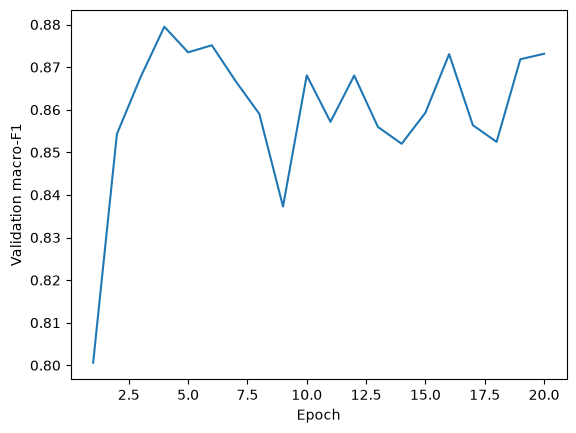

In [23]:
# 수정 금지

plt.plot([row['epoch'] for row in history], [row['val_f1'] for row in history])  # epoch별 검증 F1 그래프
plt.xlabel('Epoch')  # x축 이름
plt.ylabel('Validation macro-F1')  # y축 이름
plt.show()  # 그림 표시


## 최종 평가

저장된 best 모델을 validation 데이터로 평가합니다.
최하단 셀의 `[Final] Validation macro-F1`로 최종 설정의 성능을 확인하세요.
Task A의 학습 범위, Task B의 Loss 구현 조건, Task C의 수정 가능 범위를 지켜야 합니다. 성능 관련 배점 기준은 별도로 안내합니다.


In [24]:
# 수정 금지

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))  # 저장된 best 가중치를 다시 불러옴 (weights_only=True: 안전 로딩)
val_loss, val_f1 = evaluate(model, val_loader, loss_fn)  # 검증
print(f'[Final] Validation macro-F1: {val_f1:.4f}')  # 최종 macro-F1 출력 (채점 기준 값)


[Final] Validation macro-F1: 0.8795


## 제출

아래 파일들을 제출하세요.
- 완성한 노트북 `.ipynb`
- Best 체크포인트 `outputs/F2_1_<수험번호>.pt`

파일명에는 첫 셀의 수험번호가 자동으로 들어갑니다. 따로 이름을 바꿀 필요가 없습니다.

- 실제로 위 결과를 만드는데 사용된 체크포인트 파일만 제출하세요.

또, 노트북에 다음 내용을 반드시 포함하세요.

- 고정한 구간과 학습한 구간, 해당 설정을 위해 수정한 코드
- 선택한 Loss와 직접 구현한 코드, 해당 Loss를 선택한 이유 (주석 작성)
- 비교한 하이퍼파라미터와 validation 결과, 최종으로 선택한 설정
- epoch별 validation macro-F1과 best validation macro-F1